# Анализ поездок пользователей сервиса GoFast
Данный проект является анализом популярного сервиса аренды самокатов GoFast. Мы располагаем данными о некоторых пользователях из нескольких городов, а также об их поездках. Перед нами стоит задача проанализировать данные и проверьте некоторые гипотезы, которые могут помочь бизнесу вырасти.

## Исходные данные: 

Чтобы совершать поездки по городу, пользователи сервиса GoFast пользуются мобильным приложением. 

Сервисом можно пользоваться:
- без подписки:
    - абонентская плата отсутствует;
    - стоимость одной минуты поездки — 8 рублей;
    - стоимость старта (начала поездки) — 50 рублей;
- с подпиской Ultra:
    - абонентская плата — 199 рублей в месяц;
    - стоимость одной минуты поездки — 6 рублей;
    - стоимость старта — бесплатно.

В нашем распоряжении 3 датафрейма, в которых содержится информация: 
1. о пользователях
2. их поездках
3. подписках.

Нам предстоит:
1. посчитать суммарное расстояние, количество поездок и суммарное время для каждого пользователя за каждый месяц
2. найти сумму помесячной выручки, которую принёс каждый пользователь.

## Описание данных:

В основных данных есть информация о пользователях, их поездках и подписках.

* Пользователи — users_go.csv

user_id	- уникальный идентификатор пользователя

name - имя пользователя

age - возраст

city - город

subscription_type	тип подписки (free, ultra)

* Поездки — rides_go.csv

user_id	- уникальный идентификатор пользователя

distance - расстояние, которое пользователь проехал в текущей сессии (в метрах)

duration - продолжительность сессии (в минутах) — время с того момента, как пользователь нажал кнопку «Начать поездку» до момента, как он нажал кнопку 
«Завершить поездку»

date - дата совершения поездки

* Подписки — subscriptions_go.csv

subscription_type - тип подписки

minute_price - стоимость одной минуты поездки по данной подписке

start_ride_price - стоимость начала поездки

subscription_fee - стоимость ежемесячного платежа

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from datetime import datetime as dt
import matplotlib.pyplot as plt
from scipy import stats as st
import warnings
warnings.filterwarnings('ignore')

#### Шаг 1. Загрузка данных

In [2]:
try:
    df_users_go = pd.read_csv ('users_go.csv')
    df_rides_go = pd.read_csv ('rides_go.csv')
    df_subscriptions_go = pd.read_csv ('subscriptions_go.csv')
except:
    print ('File was not found')

In [3]:
df_users_go.head(5)

,user_id,name,age,city,subscription_type
0,1,Кира,22,Тюмень,ultra
1,2,Станислав,31,Омск,ultra
2,3,Алексей,20,Москва,ultra
3,4,Константин,26,Ростов-на-Дону,ultra
4,5,Адель,28,Омск,ultra


In [4]:
df_rides_go.head(5)

,user_id,distance,duration,date
0,1,4409.919140,25.599769,2021-01-01
1,1,2617.592153,15.816871,2021-01-18
2,1,754.159807,6.232113,2021-04-20
3,1,2694.783254,18.511000,2021-08-11
4,1,4028.687306,26.265803,2021-08-28


Дистанция в метрах, продолжительность сессии в минутах.

In [5]:
df_subscriptions_go.head(5)

,subscription_type,minute_price,start_ride_price,subscription_fee
0,free,8,50,0
1,ultra,6,0,199


В третьей таблице только 2 строки, ведь всего 2 тарифа доступно у данного сервиса в настоящий момент.

In [6]:
df_users_go.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1565 entries, 0 to 1564
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   user_id            1565 non-null   int64 
 1   name               1565 non-null   object
 2   age                1565 non-null   int64 
 3   city               1565 non-null   object
 4   subscription_type  1565 non-null   object
dtypes: int64(2), object(3)
memory usage: 61.3+ KB


In [7]:
df_subscriptions_go.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   subscription_type  2 non-null      object
 1   minute_price       2 non-null      int64 
 2   start_ride_price   2 non-null      int64 
 3   subscription_fee   2 non-null      int64 
dtypes: int64(3), object(1)
memory usage: 196.0+ bytes


In [8]:
df_rides_go.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18068 entries, 0 to 18067
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   user_id   18068 non-null  int64  
 1   distance  18068 non-null  float64
 2   duration  18068 non-null  float64
 3   date      18068 non-null  object 
dtypes: float64(2), int64(1), object(1)
memory usage: 564.8+ KB


Типы данных в датафреймах соответствуют их содержимому, кроме столбца с датой поездки в таблице с поездками. 
Отметим, что тип данных в ключевых столбцах, по которым будет производиться объединение данных, совпадают.

#### Шаг 2. Предобработка данных

Подготовим данные для дальнейшей обработки. Для начала приведем тип данных в столбце с датой.

In [9]:
df_rides_go['date'] = pd.to_datetime(df_rides_go['date'])
df_rides_go.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18068 entries, 0 to 18067
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   user_id   18068 non-null  int64         
 1   distance  18068 non-null  float64       
 2   duration  18068 non-null  float64       
 3   date      18068 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(2), int64(1)
memory usage: 564.8 KB


Изменение типа данных прошло успешно.

Создадим в таблице df_rides_go столбец с месяцем даты поездки.

In [10]:
df_rides_go['month'] = df_rides_go['date'].dt.month
df_rides_go.head(5)

,user_id,distance,duration,date,month
0,1,4409.919140,25.599769,2021-01-01,1
1,1,2617.592153,15.816871,2021-01-18,1
2,1,754.159807,6.232113,2021-04-20,4
3,1,2694.783254,18.511000,2021-08-11,8
4,1,4028.687306,26.265803,2021-08-28,8


In [11]:
df_rides_go['date'].describe()

count                            18068
mean     2021-06-30 19:47:21.266327296
min                2021-01-01 00:00:00
25%                2021-04-02 00:00:00
50%                2021-06-30 00:00:00
75%                2021-09-28 00:00:00
max                2021-12-30 00:00:00
Name: date, dtype: object

In [12]:
first_date = df_rides_go['date'].min()
last_date =  df_rides_go['date'].max()
interval = last_date-first_date
display(f'Промежуток данных о поездках:  {first_date} - {last_date} ({interval.days} дней)') 

'Промежуток данных о поездках:  2021-01-01 00:00:00 - 2021-12-30 00:00:00 (363 дней)'

Проверим таблицы на наличие пропущенных данных.

In [13]:
percent_missing = df_users_go.isnull().sum() * 100 / len(df_users_go)
display(percent_missing)

user_id              0.0
name                 0.0
age                  0.0
city                 0.0
subscription_type    0.0
dtype: float64

In [14]:
percent_missing = df_rides_go.isnull().sum() * 100 / len(df_rides_go)
display(percent_missing)

user_id     0.0
distance    0.0
duration    0.0
date        0.0
month       0.0
dtype: float64

В третьей таблице также очевидно, что пропусков не содержится.


Проверим, имеются ли в таблице дубликаты.

In [15]:
df_users_go.duplicated().sum()

31

In [16]:
df_users_go = df_users_go.drop_duplicates(keep = 'first').reset_index()

In [17]:
df_users_go.duplicated().sum()

0

Получаем таблицу с пользователями без строк-дубликатов с обновленными индексами.

In [18]:
df_rides_go.duplicated().sum()

0

В таблице с поездками явных дубликатов нет.
Теперь мы имеем готовые к обработке данные.  Без дубликатов и пропущенных значений.

Таким образом, мы привели тип данных, где это было необходимо, устранили явные дубликаты строк, а также выяснили, что имеем дело с данными, взятыми за 1 год или точнее 363 дня.


#### Шаг 3. Исследовательский анализ данных

Узнаем из каких городов нашей услугой пользуется больше клиентов:

In [19]:
df_users_go['city'].value_counts()

city
Пятигорск         219
Екатеринбург      204
Ростов-на-Дону    198
Краснодар         193
Сочи              189
Омск              183
Тюмень            180
Москва            168
Name: count, dtype: int64

Посчитаем соотношение пользователей с подпиской и без (%):

In [20]:
df_users_go['subscription_type'].value_counts(normalize=True)*100

subscription_type
free     54.432855
ultra    45.567145
Name: proportion, dtype: float64

Посмотрим на графике, как распределились возраста наших клиентов в разных городах.

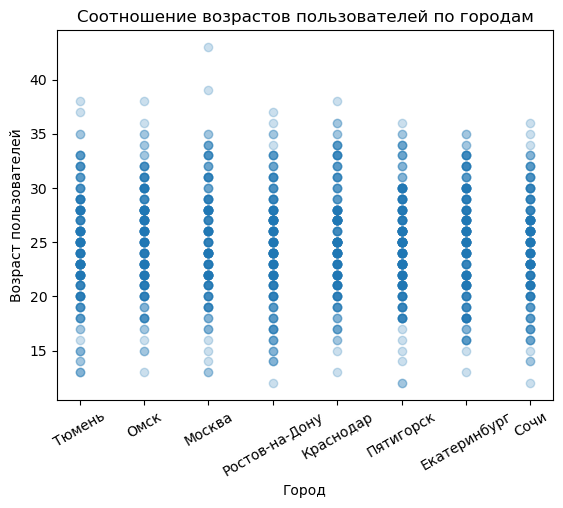

In [21]:
plt.scatter(df_users_go['city'], df_users_go['age'], alpha = 0.23)
plt.title('Соотношение возрастов пользователей по городам')  
plt.xlabel('Город') 
plt.xticks(rotation = 30)
plt.ylabel('Возраст пользователей')  
plt.show()


На графике видим распределение по возрастам наших клиентов. В Москве находится самый старший пользователь и ему более 40 лет. Самые молодые наши клиенты - на юге: Сочи, Пятигорск, Ростов-на-Дону.

Нас также интересует количественное распределение пользователей по городам.

<Axes: title={'center': 'Количество пользователей в различных городах'}, xlabel='Город', ylabel='Пользователей'>

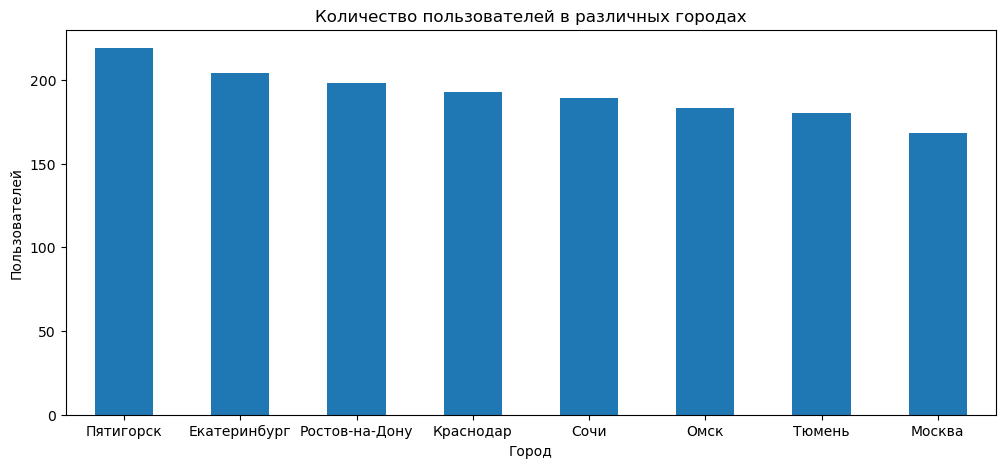

In [22]:
df_users_go['city'].value_counts().plot(kind='bar', xlabel='Город', ylabel='Пользователей', rot=0, figsize=(12,5), title = 'Количество пользователей в различных городах')

На графике визуально отобразилось соотношение пользователей по городам. Больше всего наш сервис популярен в Пятигорске и меньше всего в Москве. Конкуренты не дремлют.

In [23]:
# создадим функцию, которая принимает на вход один столбец из датасета, также можно передать
         # параметр отображения процентов (по умолчанию округление до целых процентов и наименование графика)
def pies_peaces(dataset, round_percent = '%1.0f%%', figsize=(15,8), title=''):
    #для разделения частей "пирога" в круговой диаграмме посчитаем количество уникальных значений в наименованиях городов
    pies_interval = len(dataset.unique())
    #создадим список из размеров разделителей долей
    pies_list = list([0.02 for i in range(pies_interval)])
    dataset.value_counts().plot(kind='pie', autopct=round_percent, figsize=figsize,  \
    title=title, explode = pies_list)
    

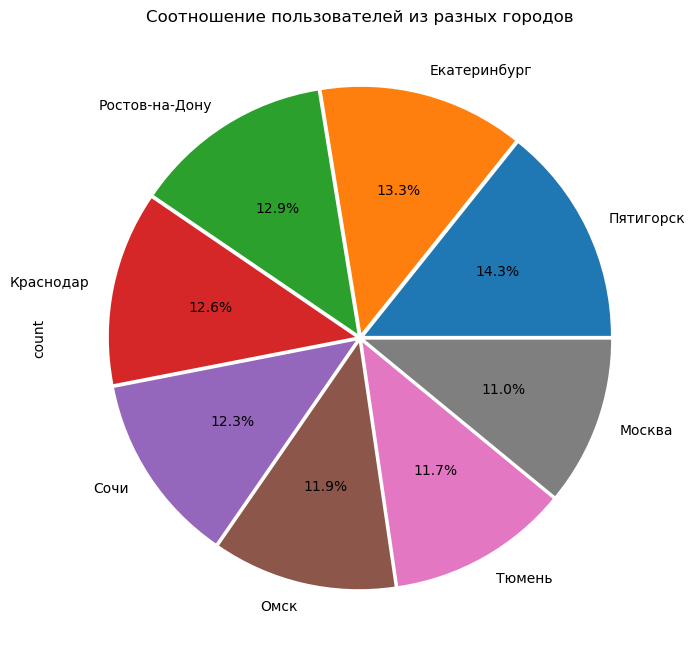

In [24]:
pies_peaces(df_users_go['city'], round_percent = '%1.1f%%', title = 'Соотношение пользователей из разных городов')

Проверим, какого возраста наши клиенты, долю каждого возраста от общего числа пользователей и визуализируем данные графически.

<Axes: title={'center': 'Распределение количества пользователей по возрастам'}, xlabel='Age', ylabel='Count'>

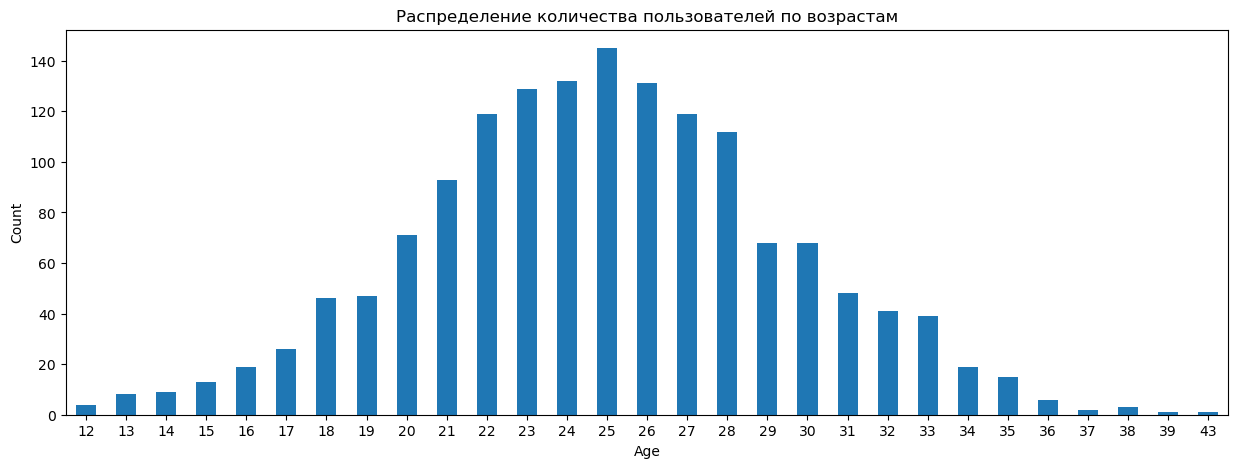

In [25]:
df_users_go['age'].sort_values().value_counts(sort=False).plot(kind='bar', xlabel='Age', ylabel='Count', rot=0, figsize=(15,5), title = 'Распределение количества пользователей по возрастам')

На графике распределения пользователей по возрастам видим "колокол", значит значения распределились нормально относительно среднего 25 лет. Самым молодым нашим пользователям по 12 лет, замыкают список наших клиентов 43-летние граждане. Наиболее популярен наш сервис среди 20-28-летней молодежи.

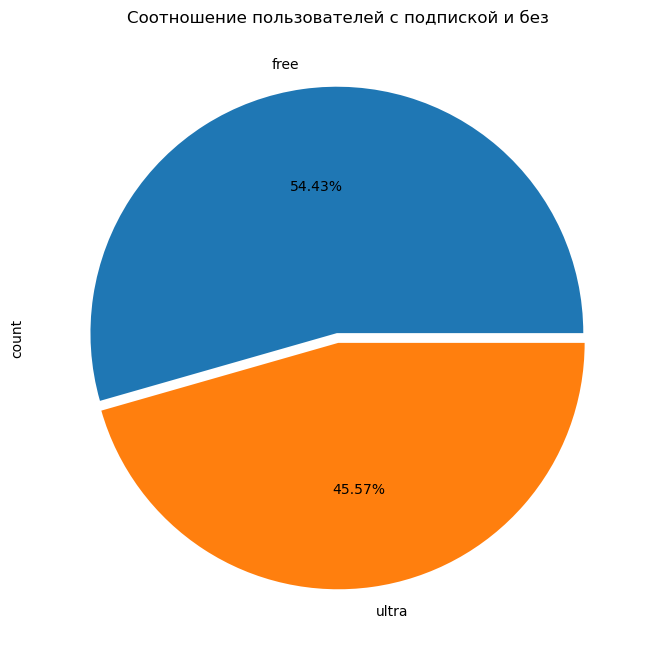

In [26]:
pies_peaces(df_users_go['subscription_type'], round_percent = '%1.2f%%', title = 'Соотношение пользователей с подпиской и без')

Круговая диаграмма демонстрирует соотношение пользователей с подпиской и без, это 45.57% против 54.43% соответственно.

Оценим визуально, продолжительность поездок всех пользователей.

Text(0, 0.5, 'Количество поездок')

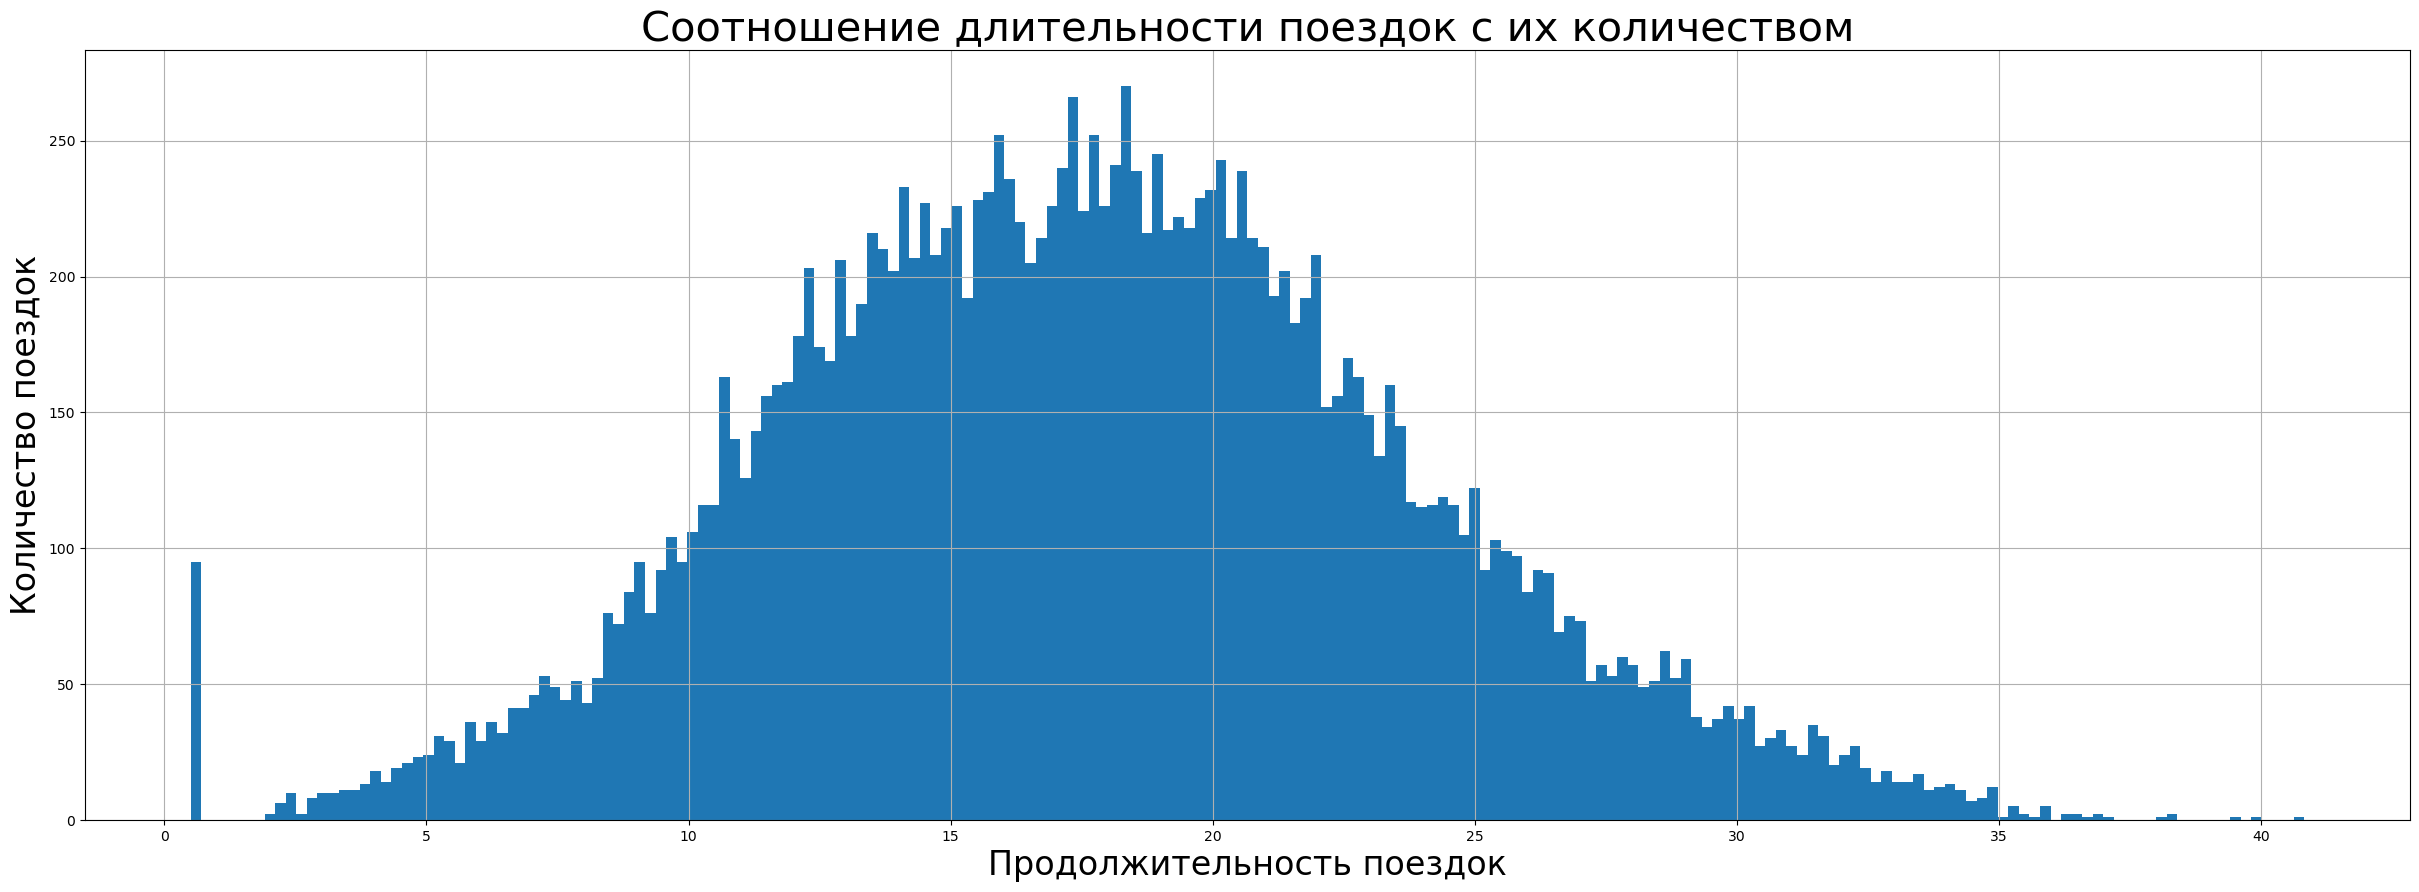

In [27]:
df_rides_go['duration'].hist(bins=200, figsize = (30,10))

plt.title('Соотношение длительности поездок с их количеством', fontsize=30)
plt.xlabel('Продолжительность поездок', fontsize=24)
plt.ylabel('Количество поездок', fontsize=24)

На гистограмме видим почти нормальное распределение значений продолжительности поездок. Выделяется также столбик около значения 1 минута. 

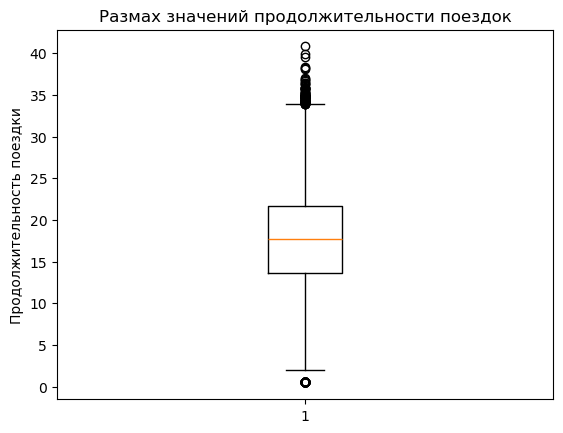

In [28]:
plt.boxplot(df_rides_go['duration'])
plt.title('Размах значений продолжительности поездок')
plt.xlabel('')
plt.ylabel('Продолжительность поездки')
plt.show()

In [29]:
df_rides_go['duration'].describe()

count    18068.000000
mean        17.805011
std          6.091051
min          0.500000
25%         13.597563
50%         17.678395
75%         21.724800
max         40.823963
Name: duration, dtype: float64

  Мы видим описательные характеристики значений продолжительности поездок, среднее и медианное значения примерно равны 18, минимальное значение 0,5 минуты и максимальное 41.
   Ящик с усами счел, что в наборе данных имеются выбросы - поезки свыше и менее среднего +-3 стандартных отклонения.

Однако же гистограмма показала нормальное распределение, следовательно удалять такие данные мы не станем и продолжим работать с полным датасетом.
  

Построим гистограмму для столбца с расстояниями поездок. Подберем количество корзин, подходящее для нашего набора данных.

Text(0, 0.5, 'Количество поездок')

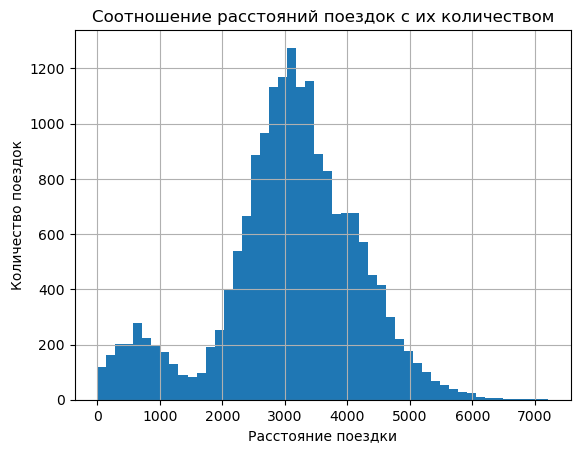

In [30]:
df_rides_go['distance'].hist(bins=50)
plt.title('Соотношение расстояний поездок с их количеством')
plt.xlabel('Расстояние поездки')
plt.ylabel('Количество поездок')


Значения начинаются около "0". Сюда могли попасть не состоявшиеся толком поездки (клиент внезапно передумал, не разобрался с управлением и т.д.).  
Однако, гистограмма получилась бимодальной, это наводит на мысль о том, что данные для исследования были склеены из двух источников.

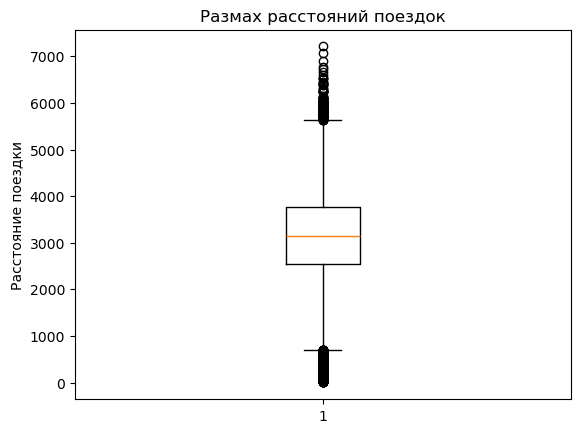

In [31]:
plt.boxplot(df_rides_go['distance'])
plt.title('Размах расстояний поездок')
plt.xlabel('')
plt.ylabel('Расстояние поездки')
plt.show()

In [32]:
df_rides_go['distance'].describe()

count    18068.000000
mean      3070.659976
std       1116.831209
min          0.855683
25%       2543.226360
50%       3133.609994
75%       3776.222735
max       7211.007745
Name: distance, dtype: float64

На диаграмме размаха видим, что остались слишком малые значения, подпадающие под понятие выбросы. Это значения от 943.64 м, что является вполне допустимым расстоянием для, к примеру, первой (пробной) поездки на самокате. Считаем целесообразным оставить их в датасете.

#### Шаг 4. Объединение данных

Объединим все данные в одну таблицу. Посчитаем длины датасетов до и после склеивания.

In [34]:
merged_data = df_users_go.merge(df_rides_go, on='user_id', how='inner') 
merged_data = merged_data.merge(df_subscriptions_go, on='subscription_type', how='inner') 
merged_data.head(15)

,index,user_id,name,age,city,subscription_type,distance,duration,date,month,minute_price,start_ride_price,subscription_fee
0,0,1,Кира,22,Тюмень,ultra,4409.919140,25.599769,2021-01-01,1,6,0,199
1,0,1,Кира,22,Тюмень,ultra,2617.592153,15.816871,2021-01-18,1,6,0,199
2,0,1,Кира,22,Тюмень,ultra,754.159807,6.232113,2021-04-20,4,6,0,199
3,0,1,Кира,22,Тюмень,ultra,2694.783254,18.511000,2021-08-11,8,6,0,199
4,0,1,Кира,22,Тюмень,ultra,4028.687306,26.265803,2021-08-28,8,6,0,199
5,0,1,Кира,22,Тюмень,ultra,2770.890808,16.650138,2021-10-09,10,6,0,199
6,0,1,Кира,22,Тюмень,ultra,3039.020292,14.927879,2021-10-19,10,6,0,199
7,0,1,Кира,22,Тюмень,ultra,2842.118050,23.117468,2021-11-06,11,6,0,199
8,0,1,Кира,22,Тюмень,ultra,3412.690668,15.238072,2021-11-14,11,6,0,199
9,0,1,Кира,22,Тюмень,ultra,748.690645,15.041884,2021-11-22,11,6,0,199


In [49]:
if len(df_rides_go) == len(merged_data):
    print ('Объединение прошло успешно')
else:
    print ('Объединение не удалось')

Объединение прошло успешно


Подготовим 2 таблицы, объединяющие данные из трех исходных таблиц, для каждого вида подписки (free и ultra).

In [36]:
merged_ultra = merged_data.query('subscription_type == "ultra"')
merged_free = merged_data.query('subscription_type == "free"')

display(merged_ultra.head())
merged_free.head()

,index,user_id,name,age,city,subscription_type,distance,duration,date,month,minute_price,start_ride_price,subscription_fee
0,0,1,Кира,22,Тюмень,ultra,4409.919140,25.599769,2021-01-01,1,6,0,199
1,0,1,Кира,22,Тюмень,ultra,2617.592153,15.816871,2021-01-18,1,6,0,199
2,0,1,Кира,22,Тюмень,ultra,754.159807,6.232113,2021-04-20,4,6,0,199
3,0,1,Кира,22,Тюмень,ultra,2694.783254,18.511000,2021-08-11,8,6,0,199
4,0,1,Кира,22,Тюмень,ultra,4028.687306,26.265803,2021-08-28,8,6,0,199


,index,user_id,name,age,city,subscription_type,distance,duration,date,month,minute_price,start_ride_price,subscription_fee
6500,699,700,Айдар,22,Омск,free,2515.690719,14.944286,2021-01-02,1,8,50,0
6501,699,700,Айдар,22,Омск,free,846.932642,16.234663,2021-02-01,2,8,50,0
6502,699,700,Айдар,22,Омск,free,4004.434142,20.016628,2021-02-04,2,8,50,0
6503,699,700,Айдар,22,Омск,free,1205.911290,9.782872,2021-02-10,2,8,50,0
6504,699,700,Айдар,22,Омск,free,3047.379435,17.427673,2021-02-14,2,8,50,0


Визуализируем данные о поздках (расстояние и продолжительность) для полученных новых таблиц в сравнении с исходными данными.

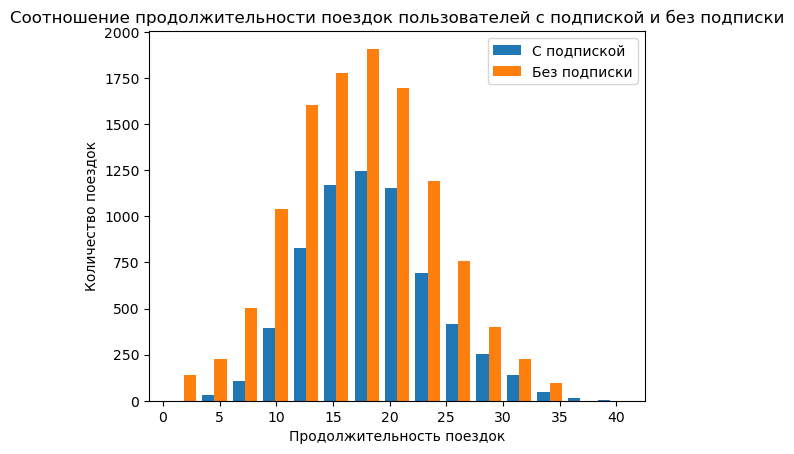

In [37]:
plt.hist([merged_ultra['duration'], merged_free['duration']], bins = 15, label=['С подпиской', 'Без подписки'])
plt.legend(loc='upper right')
plt.title('Соотношение продолжительности поездок пользователей с подпиской и без подписки')
plt.xlabel('Продолжительность поездок')
plt.ylabel('Количество поездок')
plt.show()

На столбчатой диаграмме мы видим, что значение продолжительности поездок распределилось нормально вокруг среднего примерно 17 минут. 

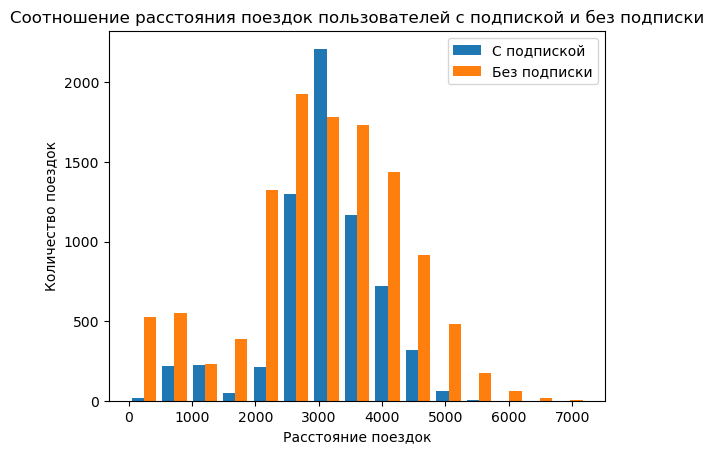

In [38]:
plt.hist([merged_ultra['distance'], merged_free['distance']], bins=15, label=['С подпиской', 'Без подписки'])
plt.legend(loc='upper right')
plt.title('Соотношение расстояния поездок пользователей с подпиской и без подписки')
plt.xlabel('Расстояние поездок')
plt.ylabel('Количество поездок')
plt.show()

На сравнительной гистограмме расстояния, которое проехали пользователи с подпиской и без, видна бимодальность, которая сообщает о возможной склейке данных и различием в единицах измерения.  БОльшая часть данных указывает на среднее значение около 3000 м.

Опираясь на предыдущие гистограммы, ожидаемо увидеть, что на пользователей без подписки приходится бОльшая часть коротких поездок (6-12 минут), остальные пропорциональны общему количеству.
Такэе очевидно, что доля пользователей без подписки больше, чем доля пользователей с подпиской.

#### Шаг 5. Подсчёт выручки

Постоим таблицу с группировкой по id пользователя и месяцу поездки. Посчитаем общий "пробег" клиента в каждом месяце, количество поездок каждого пользователя по месяцам и общее время поездок.

In [39]:
data_pivot = merged_data.groupby(['user_id', 'month']).agg({
    'distance': 'sum',
    'duration': ['count', 'sum']})
data_pivot.columns = ['distance_sum', 'sessions_count', ' duration_sum']
data_pivot.head(15)

distance_sum  sessions_count   duration_sum
user_id month                                             
1       1       7027.511294               2      41.416640
        4        754.159807               1       6.232113
        8       6723.470560               2      44.776802
        10      5809.911100               2      31.578017
        11      7003.499363               3      53.397424
        12      6751.629942               2      27.203912
2       3      10187.723006               3      60.959959
        4       6164.381824               2      39.048633
        6       3255.338202               1      13.851127
        7       6780.722964               2      46.170157
        8        923.007439               1       6.914760
        10      2824.636598               1      18.779128
        12      3828.248580               1      11.920514
3       1       3061.777147               1      12.654443
        2       5421.152016               2      37.568637

Добавим столбец с суммой выручки по месяцам, полученной с каждого пользователя, пока без учета подписки.

In [40]:
merged_data ['income'] = round((merged_data['duration'] * merged_data['minute_price'] + merged_data['start_ride_price']), 2)
merged_data.head()

,index,user_id,name,age,city,subscription_type,distance,duration,date,month,minute_price,start_ride_price,subscription_fee,income
0,0,1,Кира,22,Тюмень,ultra,4409.919140,25.599769,2021-01-01,1,6,0,199,153.60
1,0,1,Кира,22,Тюмень,ultra,2617.592153,15.816871,2021-01-18,1,6,0,199,94.90
2,0,1,Кира,22,Тюмень,ultra,754.159807,6.232113,2021-04-20,4,6,0,199,37.39
3,0,1,Кира,22,Тюмень,ultra,2694.783254,18.511000,2021-08-11,8,6,0,199,111.07
4,0,1,Кира,22,Тюмень,ultra,4028.687306,26.265803,2021-08-28,8,6,0,199,157.59


Вновь создадим таблицу с группировкой, добавив столбец о стоимости подписки и подсчетом суммы поездок по месяцам.

In [41]:
data_pivot = merged_data.groupby(['user_id', 'subscription_fee', 'month'], group_keys=False).agg({
    'distance': 'sum',
    'duration': ['count', 'sum'],
    'income': 'sum'}).reset_index()
#сразу избавились от мультииндекса и далее переименуем вычисляемые столбцы  
data_pivot.columns = ['user_id','subscription_fee',	'month','distance_sum', 'sessions_count', ' duration_sum', 'income_sum']
data_pivot.head(15)

,user_id,subscription_fee,month,distance_sum,sessions_count,duration_sum,income_sum
0,1,199,1,7027.511294,2,41.416640,248.50
1,1,199,4,754.159807,1,6.232113,37.39
2,1,199,8,6723.470560,2,44.776802,268.66
3,1,199,10,5809.911100,2,31.578017,189.47
4,1,199,11,7003.499363,3,53.397424,320.38
5,1,199,12,6751.629942,2,27.203912,163.23
6,2,199,3,10187.723006,3,60.959959,365.77
7,2,199,4,6164.381824,2,39.048633,234.29
8,2,199,6,3255.338202,1,13.851127,83.11
9,2,199,7,6780.722964,2,46.170157,277.02


Для работы с мультииндексом сводной таблицы сбросим индексы и установим целочисленный тип значения для стоимости подписки.

In [42]:
data_pivot['sum_income_month'] = data_pivot['income_sum'] + data_pivot['subscription_fee']
data_pivot.head(10)

,user_id,subscription_fee,month,distance_sum,sessions_count,duration_sum,income_sum,sum_income_month
0,1,199,1,7027.511294,2,41.416640,248.50,447.50
1,1,199,4,754.159807,1,6.232113,37.39,236.39
2,1,199,8,6723.470560,2,44.776802,268.66,467.66
3,1,199,10,5809.911100,2,31.578017,189.47,388.47
4,1,199,11,7003.499363,3,53.397424,320.38,519.38
5,1,199,12,6751.629942,2,27.203912,163.23,362.23
6,2,199,3,10187.723006,3,60.959959,365.77,564.77
7,2,199,4,6164.381824,2,39.048633,234.29,433.29
8,2,199,6,3255.338202,1,13.851127,83.11,282.11
9,2,199,7,6780.722964,2,46.170157,277.02,476.02


Столбец sum_income_month отражает всю сумму дохода от каждого пользователя по месяцам с учетом подписки.

#### Шаг 6. Проверка гипотез

6.1 Передо мной стоит задача проверить, являются ли клиенты с подпиской более выгодными для компании. А именно, тратят ли они больше времени на поездки.
Для этого сформулируем нулевую гипотезу. Среднее генеральной совокупности продолжительности поездок пользователей с подпиской равно среднему генеральной совокупности продолжительности поездок пользователей без подписки. 
Алернативной гипотезой будет результат, когда среднее генеральной совокупности продолжительности поездок пользователей с подпиской больше среднего генеральной совокупности продолжительности поездок пользователей без подписки. 
Таким образом у нас правосторонняя альтернативная гипотеза.

In [43]:
users_subscribe_ultra = merged_ultra['duration']
users_subscribe_free = merged_free['duration']
alpha = 0.01 # уровень статистической значимости
# если p-value окажется меньше него, отвергнем гипотезу

results = st.ttest_ind(users_subscribe_ultra, users_subscribe_free, alternative = 'greater')

print('p-значение:', results.pvalue)

if results.pvalue < alpha:
    print('Пользователи с подпиской тратят больше времени на поездки')
else:
    print('Не удалось отвергнуть теорию, что средние продолжительности поездок пользователей с подпиской и без равны') 

print(f'Средняя продолжительность поездки с подпиской = {users_subscribe_ultra.mean()}')
print(f'Средняя продолжительность поездки без подписки = {users_subscribe_free.mean()}')

p-значение: 1.2804098316645618e-34
Пользователи с подпиской тратят больше времени на поездки
Средняя продолжительность поездки с подпиской = 18.54198516280583
Средняя продолжительность поездки без подписки = 17.39090929866399


Проверив гипотезу получаем ответ на вопрос о том, выгоднее ли для компании пользователи с подпиской. Гипотеза, что пользователи с подпиской тратят больше времени на поездки подтвердилась.

6.2 Следующей проверим гипотезу о том, составляет ли средняя поездка пользователя с подпиской менее 3130 м. 
Так мы сможем понять, не превышаются ли нормы износа самоката.

Нулевая гипотеза: Средние продолжительности поездок пользователей с подпиской  равны 3130 м

Альтернативная гипотеза: Пользователи с подпиской в среднем за одну поздку проезжают более 3130 м

Метод правосторонний

In [44]:
users_subscribe_ultra = merged_ultra['distance']

alpha = 0.01 # уровень статистической значимости

normal_distance = 3130
results = st.ttest_1samp(users_subscribe_ultra, normal_distance, alternative = 'greater')

print('p-значение:', results.pvalue)

if results.pvalue < alpha:
    print(f'Пользователи с подпиской в среднем за одну поздку проезжают более {normal_distance}')
else:
    print(f'Не удалось отвергнуть теорию, что средние продолжительности поездок пользователей с подпиской  равны {normal_distance}') 

p-значение: 0.9195368847849785
Не удалось отвергнуть теорию, что средние продолжительности поездок пользователей с подпиской  равны 3130


Такис образом, имея уровень статистической значимости 1%, мы можем утверждать, что  пользователи с подпиской за одну поездку в среднем проезжают не более 3130 м. 
Следовательно, самокаты такими клиентами эксплуатируются в нормальном режиме и износ не превышает допустимый.

6.3 Проверим гипотезу о том, будет ли помесячная выручка от пользователей с подпиской по месяцам выше, чем выручка от пользователей без подписки.

Нулевая гипотеза: Средние значения выручек по месяцам от пользователей с подпиской и без равны

Альтернативная гипотеза: Пользователи с подпиской приносят больше выручки компании

Правосторонний метод

In [45]:
users_subscribe_ultra = data_pivot.query('subscription_fee == 199')['sum_income_month']
users_subscribe_free = data_pivot.query('subscription_fee == 0')['sum_income_month']
alpha = 0.01 # уровень статистической значимости


results = st.ttest_ind(users_subscribe_ultra, users_subscribe_free, alternative = 'greater')

print('p-значение:', results.pvalue)

if results.pvalue < alpha:
    print('Пользователи с подпиской приносят больше выручки компании')
else:
    print('Не удалось отвергнуть теорию, что средние выручек по месяцам от пользователей с подпиской и без равны') 
print(f'Средняя выручка от пользователя с подпиской = {users_subscribe_ultra.mean()}')
print(f'Средняя от пользователей без подписки = {users_subscribe_free.mean()}')

p-значение: 2.900274808149586e-37
Пользователи с подпиской приносят больше выручки компании
Средняя выручка от пользователя с подпиской = 358.52728877123315
Средняя от пользователей без подписки = 321.8335289791115


Установив уровень статистической значимости 1%, мы можем утверждать, что пользователи с подпиской приносят в среднем больше, чем клиенты без подписки.

Проверив 3 различные гипотезы можно сделать вывод о том, что клиенты с подпиской это лучшие клиенты для компании, т.к. они ездят больше, приносят больше выручки и не совершают поездки свыше рекомендованной дистанции.
Компании следует рассмотреть возможность проведения маркетинговых акций для привлечения пользователей с подпиской.

<b>Общий вывод:</b>

Произведен анализ данных о поездках пльзователей сервиса GOFAST за период: 01.01.2021 - 30.12.2021-01.01  (363 дней)

Пропусков и дубликатов в процессе предобработки данных не обнаружено.

Возможно, представленные данные имеют синтетическую происхождение, т.к. присутствует бимодальность расстояния поездок.

Согласно данной выборке наибольшее количество пользователей зафиксировано в Пятигорске (14%), наименьшее – в Москве (11%).
В Москве находится самый старший пользователь и ему более 40 лет. Самые молодые наши клиенты - на юге: Сочи, Пятигорск, Ростов-на-Дону.

Самым молодым нашим пользователям по 12 лет, замыкают список наших клиентов 43-летние граждане. Наиболее популярен наш сервис среди 20-28-летней молодежи.

Доля пользователей без подписки больше, чем доля пользователей с подпиской.

Пользователи с подпиской тратят больше времени на поездки. Вывод: пользователи с подпиской приносят больше выгоды компании.

Установив уровень статистической значимости 1%, можно утверждать, что пользователи с подпиской за одну поездку в среднем проезжают менее 3130 м. Следовательно, самокаты такими клиентами эксплуатируются в нормальном режиме и износ не превышает допустимый.

Установив уровень статистической значимости 1%, мы можем утверждать, что пользователи с подпиской приносят в среднем по месяцам больше, чем клиенты без подписки.

<b>Итоговый вывод:</b> клиенты с подпиской - это лучшие клиенты для компании, т.к. они ездят больше, приносят больше выручки и не совершают поездки свыше рекомендованной дистанции. Компании следует рассмотреть возможность проведения маркетинговых акций для привлечения пользователей с подпиской.


#### Шаг 7. Распределения

7.1 Отделу маркетинга GoFast поставили задачу: нужно провести акцию с раздачей промокодов на один бесплатный месяц подписки, в рамках которой как минимум 100 существующих клиентов должны продлить эту подписку. То есть по завершении периода действия подписки пользователь может либо отказаться от неё, либо продлить, совершив соответствующий платёж. 
Эта акция уже проводилась ранее и по итогу выяснилось, что после бесплатного пробного периода подписку продлевают 10 % пользователей. Выясните, какое минимальное количество промокодов нужно разослать, чтобы вероятность не выполнить план была примерно 5 %. Подберите параметры распределения, описывающего эту ситуацию, постройте график распределения и сформулируйте ответ на вопрос о количестве промокодов.

1. Построим распределение вероятности. посколько исходов всего 2: пользователь либо продлевает подписку, либо нет, то мы имеем дело с биномиальным распределением, затем апроксимируем его нормальным.

Необходимо разослать не менее 1161 промокодов, чтобы  вероятность не выполнить план была менее 5.0 %


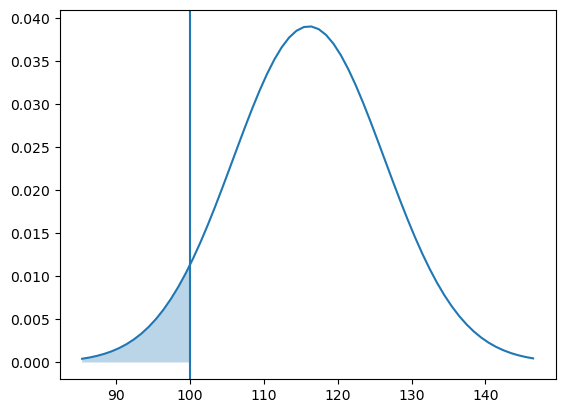

In [46]:
from math import factorial
from scipy.stats import binom

n = 1000
p = 0.1
k=99
cdf = 0.05
while cdf < binom.cdf(k, n, p):
    n += 1
print(f'Необходимо разослать не менее {n} промокодов, чтобы  вероятность не выполнить план была менее {binom.cdf(k, n, p).round(2)*100} %')

mu = n*p
sigma = (n*p*(1-p))**0.5
distr = []
x = np.arange(mu - 3 * sigma, mu + 3 * sigma)

distr = st.norm.pdf(x, mu, sigma)

px = np.linspace(mu - 3 * sigma, k+1, 1000)
plt.plot(x, distr)
plt.axvline(x=k+1)
plt.fill_between(px, st.norm.pdf(px, mu, sigma), alpha = 0.3)
plt.show()


Необходимо разослать не менее 1161 промокодов, чтобы вероятность не выполнить план была менее 5%.

7.2 Отдел маркетинга рассылает клиентам push-уведомления в мобильном приложении. Клиенты могут открыть его или не открывать. Известно, что уведомления открывают около 40 % получивших клиентов. Отдел планирует разослать 1 млн уведомлений. С помощью аппроксимации постройте примерный график распределения и оцените вероятность того, что уведомление откроют не более 399,5 тыс. пользователей.

Вероятность, что уведомления откроют не более 399500 пользователей составляет 15.37%


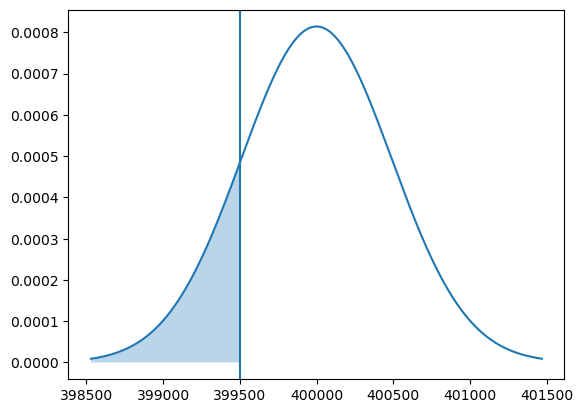

In [47]:
n = 1000000
p = 0.4
k=399500
mu = n*p
sigma = (n*p*(1-p))**0.5
distr = st.norm(mu, sigma) 

cdf = distr.cdf(k)
print(f'Вероятность, что уведомления откроют не более {k} пользователей составляет {cdf:.2%}')

px = np.linspace(mu - 3 * sigma, k, 1000)
x = np.arange(mu - 3 * sigma, mu + 3 * sigma)
plt.plot(x, st.norm.pdf(x, mu, sigma))
plt.axvline(x=k)
plt.fill_between(px, st.norm.pdf(px, mu, sigma), alpha = 0.3)
plt.show()

Вероятность, что уведомления откроют не более 399500 пользователей составляет 15.37%.